# OSM classes: predicted vs measured roughness

One block per `surface` value, its `smoothness` values below. The **prior** (orange) is what the map's *OSM* mode
shows: per class (one per surface x smoothness tag pair) the median measured roughness of its link directions with
information ≥ 3 (estimate.py). A class with fewer than 20 such link directions takes the prior of all links of its
surface (the diamond then shows that), and with fewer than 20 on the surface too it isn't predictable (grey on the
map). Shown: the 24 most common combinations (by length) with at least 10
measured link directions. Right: km of links with this combination, and how many link directions are measured
well enough (information ≥ 3).

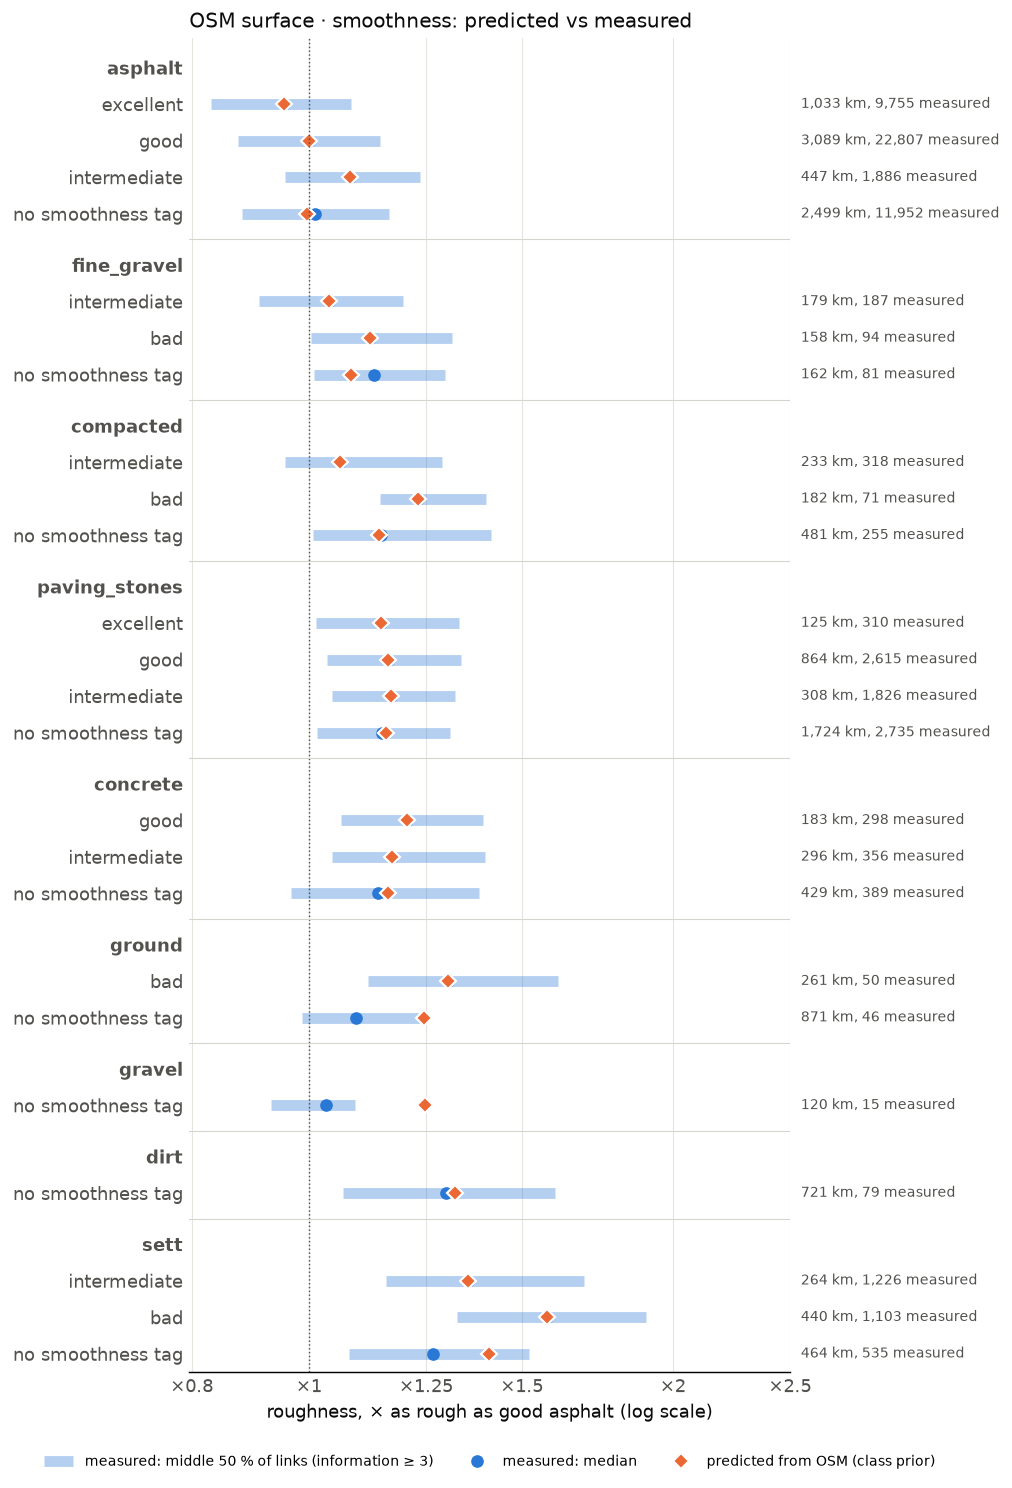

                                 km  prior        n   q25   med   q75
surface       smoothness                                             
asphalt       excellent     1032.73   0.95   9755.0  0.83  0.95  1.08
              good          3088.98   1.00  22807.0  0.87  1.00  1.15
              intermediate   447.23   1.08   1886.0  0.96  1.08  1.24
              —             2498.91   1.00  11952.0  0.88  1.01  1.17
fine_gravel   intermediate   179.02   1.04    187.0  0.91  1.04  1.20
              bad            158.03   1.12     94.0  1.00  1.12  1.31
              —              161.95   1.08     81.0  1.01  1.13  1.29
compacted     intermediate   232.72   1.06    318.0  0.96  1.06  1.29
              bad            181.81   1.23     71.0  1.15  1.23  1.40
              —              480.52   1.14    255.0  1.01  1.15  1.42
paving_stones excellent      125.10   1.15    310.0  1.01  1.15  1.33
              good           864.48   1.16   2615.0  1.03  1.16  1.34
              interm

In [1]:
import sys
sys.path.insert(0, "../pipeline")
from figures import *

def osm_classes(top: int = 24, min_measured: int = 10):
    """predicted (OSM prior) vs measured roughness for the most common surface x smoothness tag classes with
    data (>= min_measured link directions of information >= MIN_INFO and a prior), one block per surface"""
    links = pd.read_parquet(LINKS, columns=["link_id", "length", "surface", "smoothness"])
    est = pd.read_parquet(LINKS_EST).merge(links, on="link_id")
    est[["surface", "smoothness"]] = est[["surface", "smoothness"]].fillna("—")
    key = ["surface", "smoothness"]
    measured = est[est.information >= MIN_INFO].groupby(key).est
    t = pd.DataFrame({"km": est.groupby(key).length.sum() / 2000,      # two directions per two-way link
                      "prior": est.groupby(key).prior.median(), "n": measured.size(),
                      "q25": measured.quantile(0.25), "med": measured.median(), "q75": measured.quantile(0.75)})
    t = t[(t.n >= min_measured) & t.prior.notna()].sort_values("km", ascending=False).head(top).reset_index()
    t[["prior", "q25", "med", "q75"]] = np.exp(t[["prior", "q25", "med", "q75"]])     # x as rough as good asphalt
    t["first"] = t.groupby("surface").prior.transform("min")                          # blocks: smoothest first
    t["order"] = t.smoothness.map({s: i for i, s in enumerate(SMOOTHNESS)}).fillna(len(SMOOTHNESS) - 1.5)
    t = t.sort_values(["first", "surface", "order"])

    y, labels, heads, rows = 0, [], [], []
    for surface, g in t.groupby("surface", sort=False):
        heads.append(y)
        labels.append(surface if surface != "—" else "no surface tag")
        for sm in g.smoothness:
            y += 1
            rows.append(y)
            labels.append(sm if sm != "—" else "no smoothness tag")
        y += 1.4
    t["y"] = rows

    fig, ax = plt.subplots(figsize=(8, 0.27 * y + 1.6))
    ax.hlines(t.y, t.q25, t.q75, color=BLUE, alpha=0.35, lw=6,
              label=f"measured: middle 50 % of links (information ≥ {MIN_INFO:g})")
    ax.plot(t.med, t.y, "o", color=BLUE, ms=6, label="measured: median")
    ax.plot(t.prior, t.y, "D", color=ORANGE, ms=6, mec="white", mew=1.2, label="predicted from OSM (class prior)")
    ax.axvline(1, color=MUTED, lw=0.8, ls=":")
    for h in heads[1:]:
        ax.axhline(h - 0.7, color="#d6d4cd", lw=0.6)
    ax.set_yticks(heads + rows, [labels[i] for i in np.argsort(np.argsort(heads + rows))])
    for lbl in ax.get_yticklabels():
        if lbl.get_position()[1] in heads:
            lbl.set(fontweight="bold", color=INK)
    for r in t.itertuples():
        ax.annotate(f"{r.km:,.0f} km, {r.n:,.0f} measured", (1.0, r.y), xycoords=("axes fraction", "data"),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=MUTED)
    ax.set_ylim(y - 0.9, -0.8)
    ax.set_xscale("log")
    ticks = [0.8, 1, 1.25, 1.5, 2, 2.5]
    ax.set_xticks(ticks, [f"×{v:g}" for v in ticks])
    ax.minorticks_off()
    ax.set_xlabel("roughness, × as rough as good asphalt (log scale)", color=INK)
    ax.set_title("OSM surface · smoothness: predicted vs measured", color=INK, loc="left", fontsize=11)
    ax.grid(axis="x", color="#e5e4df", lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, length=0)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.6 / (0.27 * y + 1.6)), ncol=3, frameon=False, fontsize=8)
    fig.tight_layout()
    return fig, t.set_index(key)[["km", "prior", "n", "q25", "med", "q75"]]

fig, table = osm_classes()
table